# Horse Segmentation — Skip Connections in Encoder-Decoder
**Self-contained notebook for Google Colab & VS Code Colab Extension**

> **Runtime setup:** In the top-right kernel selector, ensure you are connected to **Google Colab (T4 GPU)**.
> **Zero manual uploads needed!** Cell 1 automatically restores the full project codebase (`src/`, `configs/`, `main.py`) directly onto the Colab machine.

In [2]:
# 1. Verify GPU availability
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Auto-Restore Project Source Code & Install Dependencies
Extracts all necessary modules (`src/`, `configs/`, `main.py`, `requirements.txt`) into `/content` in less than 1 second, so you do not need to upload anything.

In [5]:
import os, sys, io, base64, zipfile

# Auto-restore source code onto Colab
if not os.path.exists("src/models.py"):
    print("--> Restoring project source code onto Colab filesystem...")
    CODE_B64 = "..."
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(CODE_B64))) as z:
        z.extractall(".")
    print("✔ All source code files restored successfully!")
else:
    print("✔ Project source code is already present.")

# Ensure current working directory is on sys.path so "src" is always found
cwd = os.path.abspath(".")
if cwd not in sys.path:
    sys.path.insert(0, cwd)

# Install dataset helper and YAML parser
!pip -q install kagglehub pyyaml
print("✔ Environment ready.")

--> Restoring project source code onto Colab filesystem...
✔ All source code files restored successfully!
✔ Environment ready.


## 2. Download Weizmann Horse Dataset (327 Pairs)
Downloads the dataset using `kagglehub` directly onto Colab in seconds.

In [6]:
import os, shutil, kagglehub

# Check if dataset is already present or needs downloading
if not os.path.exists("data/cache_256.npz") and not os.path.exists("data/raw") and not os.path.exists("data/horse"):
    print("--> Downloading Weizmann Horse dataset via kagglehub...")
    path = kagglehub.dataset_download("ztaihong/weizmann-horse-database")
    print("✔ Downloaded to:", path)
    os.makedirs("data", exist_ok=True)
    if not os.path.exists("data/raw"):
        try:
            os.symlink(path, "data/raw")
        except Exception:
            shutil.copytree(path, "data/raw", dirs_exist_ok=True)

# Verify image-mask pairs
from src.data import discover_pairs
pairs, unpaired = discover_pairs("data/raw") if os.path.exists("data/raw") else discover_pairs("data")
print(f"✔ Successfully discovered {len(pairs)} matched image/mask pairs!")
if pairs:
    print("Example pair:", pairs[0])

--> Downloading Weizmann Horse dataset via kagglehub...


100%|██████████| 113M/113M [00:07<00:00, 15.8MB/s] 

Extracting files...


✔ Downloaded to: /root/.cache/kagglehub/datasets/ztaihong/weizmann-horse-database/versions/1
✔ Successfully discovered 327 matched image/mask pairs!
Example pair: (PosixPath('data/raw/weizmann_horse_db/horse/horse001.png'), PosixPath('data/raw/weizmann_horse_db/mask/horse001.png'))


## 3. Run Pipeline on T4 GPU
Executes the full experimental pipeline (~20-30 min on T4 GPU):
- Hyperparameter tuning on Baseline (Loss + LR grid search)
- Training 4 architectures: Baseline (No Skip), P1 (Concat), P2 (Additive), P3 (Transposed Conv)
- Skip connection knockout ablation study
- Hypothesis testing (Paired t-test, Wilcoxon, McNemar)
- Error localization & boundary F1 analysis
- Automated figure and report generation

In [7]:
# Run Full Pipeline (~20-30 min on T4 GPU)
!python main.py --stage all --config configs/quick.yaml --results_dir results_quick

Device: cuda | results -> results_quick
Split sizes: train 228 | val 49 | test 50
Audit: {'n_pairs': 327, 'split_sizes': {'train': 228, 'val': 49, 'test': 50}, 'empty_masks': 0}

=== Tuning stage A: loss selection (validation split) ===
  tune_baseline_noskip_bce_lr0.001_s0 | ep   1 | train 0.5326 | val loss 1.1265 dice 0.4537 iou 0.3111
  tune_baseline_noskip_bce_lr0.001_s0 | ep   2 | train 0.3861 | val loss 0.5688 dice 0.5607 iou 0.4103
  tune_baseline_noskip_bce_lr0.001_s0 | ep   4 | train 0.3001 | val loss 0.3739 dice 0.6986 iou 0.5518
  tune_baseline_noskip_bce_lr0.001_s0 | ep   6 | train 0.3014 | val loss 0.3288 dice 0.6950 iou 0.5434
  tune_baseline_noskip_bce_lr0.001_s0 | ep   8 | train 0.2344 | val loss 0.2384 dice 0.7880 iou 0.6619
  tune_baseline_noskip_bce_lr0.001_s0 | ep  10 | train 0.2056 | val loss 0.1971 dice 0.8415 iou 0.7315
  tune_baseline_noskip_bce_lr0.001_s0 | ep  12 | train 0.1805 | val loss 0.1755 dice 0.8473 iou 0.7400
  tune_baseline_noskip_bce_lr0.001_s0 | ep

## 4. Visualize Results & Key Figures
Renders the executive summary table and all evaluation figures.

In [8]:
from IPython.display import Markdown, Image, display
import os

# Choose active results directory
RESULTS_DIR = "results_quick" if os.path.exists("results_quick/summary.md") else "results"
summary_path = f"{RESULTS_DIR}/summary.md"

if os.path.exists(summary_path):
    display(Markdown(open(summary_path).read()))
else:
    print(f"{summary_path} not found. Please run the training stage first.")

# Results summary (auto-generated by `python main.py --stage analyze`)

Selected loss: **bce_dice**, learning rate(s): {'baseline_noskip': 0.0003, 'p1_concat_interp': 0.0003, 'p2_add_interp': 0.0003, 'p3_concat_tconv': 0.0003} (selection mode: shared). Seeds: [0]. Threshold: 0.5. Test images: 50.

## Main test results (mean ± std over seeds; per-image average)

| Model | skip | upsampling | precision | recall | f1 | iou | bf1 | hd95 | iou_micro |
|---|---|---|---|---|---|---|---|---|---|
| Baseline (no skip) | none | interp | 0.9266 ± 0.0000 | 0.9438 ± 0.0000 | 0.9345 ± 0.0000 | 0.8781 ± 0.0000 | 0.7618 ± 0.0000 | 8.5901 ± 0.0000 | 0.8808 ± 0.0000 |
| P1: Concat skip | concat | interp | 0.9408 ± 0.0000 | 0.9541 ± 0.0000 | 0.9466 ± 0.0000 | 0.8997 ± 0.0000 | 0.8351 ± 0.0000 | 8.4516 ± 0.0000 | 0.8998 ± 0.0000 |
| P2: Additive skip | add | interp | 0.9328 ± 0.0000 | 0.9489 ± 0.0000 | 0.9393 ± 0.0000 | 0.8877 ± 0.0000 | 0.8269 ± 0.0000 | 9.9337 ± 0.0000 | 0.8875 ± 0.0000 |
| P3: Concat + TransConv | concat | tconv | 0.9398 ± 0.0000 | 0.9507 ± 0.0000 | 0.9445 ± 0.0000 | 0.8961 ± 0.0000 | 0.8248 ± 0.0000 | 8.2798 ± 0.0000 | 0.8964 ± 0.0000 |

## Paired significance tests on the test images (seed-averaged)

| comparison | metric | mean_diff | ci95_low | ci95_high | wilcoxon_p | images_improved_% |
|---|---|---|---|---|---|---|
| P1: Concat skip vs Baseline (no skip) | IoU | 0.02162 | 0.01582 | 0.02696 | 4.441e-09 | 86 |
| P1: Concat skip vs Baseline (no skip) | F1 (Dice) | 0.01211 | 0.008761 | 0.01515 | 7.547e-09 | 86 |
| P1: Concat skip vs Baseline (no skip) | Boundary F1 | 0.07334 | 0.06067 | 0.0858 | 3.375e-14 | 96 |
| P1: Concat skip vs Baseline (no skip) | HD95 (px) | -0.1384 | -1.195 | 1.186 | 0.1172 | 66 |
| P2: Additive skip vs Baseline (no skip) | IoU | 0.009595 | -0.003226 | 0.02051 | 0.002276 | 72 |
| P2: Additive skip vs Baseline (no skip) | F1 (Dice) | 0.004764 | -0.003238 | 0.01135 | 0.002198 | 72 |
| P2: Additive skip vs Baseline (no skip) | Boundary F1 | 0.06516 | 0.05131 | 0.07818 | 7.151e-11 | 92 |
| P2: Additive skip vs Baseline (no skip) | HD95 (px) | 1.344 | -0.6421 | 3.7 | 0.6851 | 56 |
| P3: Concat + TransConv vs Baseline (no skip) | IoU | 0.01797 | 0.01095 | 0.02393 | 5.07e-06 | 78 |
| P3: Concat + TransConv vs Baseline (no skip) | F1 (Dice) | 0.01001 | 0.006004 | 0.01342 | 5.367e-06 | 78 |
| P3: Concat + TransConv vs Baseline (no skip) | Boundary F1 | 0.063 | 0.05111 | 0.07387 | 7.656e-12 | 90 |
| P3: Concat + TransConv vs Baseline (no skip) | HD95 (px) | -0.3103 | -1.357 | 0.7335 | 0.08645 | 60 |
| P2: Additive skip vs P1: Concat skip | IoU | -0.01202 | -0.02385 | -0.002768 | 0.05936 | 38 |
| P2: Additive skip vs P1: Concat skip | F1 (Dice) | -0.007341 | -0.01465 | -0.001647 | 0.06489 | 38 |
| P2: Additive skip vs P1: Concat skip | Boundary F1 | -0.008178 | -0.01795 | 0.0007269 | 0.1813 | 44 |
| P2: Additive skip vs P1: Concat skip | HD95 (px) | 1.482 | -0.01826 | 3.493 | 0.04325 | 38 |
| P3: Concat + TransConv vs P1: Concat skip | IoU | -0.003642 | -0.009223 | 0.001557 | 0.2297 | 50 |
| P3: Concat + TransConv vs P1: Concat skip | F1 (Dice) | -0.002098 | -0.005325 | 0.0009412 | 0.2223 | 50 |
| P3: Concat + TransConv vs P1: Concat skip | Boundary F1 | -0.01034 | -0.02098 | -0.0005743 | 0.07083 | 40 |
| P3: Concat + TransConv vs P1: Concat skip | HD95 (px) | -0.1719 | -1.814 | 1.211 | 0.378 | 36 |

## Error location (% of image pixels)

| model | err_band | err_far |
|---|---|---|
| Baseline (no skip) | 2.5046 | 0.8164 |
| P1: Concat skip | 1.8872 | 0.8719 |
| P2: Additive skip | 1.9195 | 1.2057 |
| P3: Concat + TransConv | 1.9675 | 0.8874 |

## Efficiency

| model | params | size_mb | infer_ms | train_time_s | best_epoch | val_dice |
|---|---|---|---|---|---|---|
| Baseline (no skip) | 6457441 | 24.633 | 5.954 | 113.000 | 38.000 | 0.919 |
| P1: Concat skip | 7240801 | 27.621 | 7.135 | 127.100 | 40.000 | 0.934 |
| P2: Additive skip | 6457441 | 24.633 | 6.176 | 114.400 | 38.000 | 0.932 |
| P3: Concat + TransConv | 7763041 | 29.614 | 12.069 | 111.200 | 38.000 | 0.934 |

## Skip knock-out (test IoU)

| variant | p1_concat_interp | p2_add_interp | p3_concat_tconv |
|---|---|---|---|
| none dropped | 0.8997 | 0.8877 | 0.8961 |
| drop L1 | 0.8980 | 0.8834 | 0.8943 |
| drop L2 | 0.8863 | 0.8700 | 0.8837 |
| drop L3 | 0.8403 | 0.8390 | 0.8164 |
| drop L4 | 0.8719 | 0.8638 | 0.8598 |
| drop all | 0.6706 | 0.6643 | 0.6909 |

## Tuning (validation Dice)

Loss table: {'bce_dice': 0.886355, 'bce': 0.877795}

LR table: {'0.0003': {'baseline_noskip': 0.90214, 'p1_concat_interp': 0.91662, 'p2_add_interp': 0.91416, 'p3_concat_tconv': 0.91209}, '0.001': {'baseline_noskip': 0.88601, 'p1_concat_interp': 0.8867, 'p2_add_interp': 0.89527, 'p3_concat_tconv': 0.90524}}



=== ARCHITECTURE ===


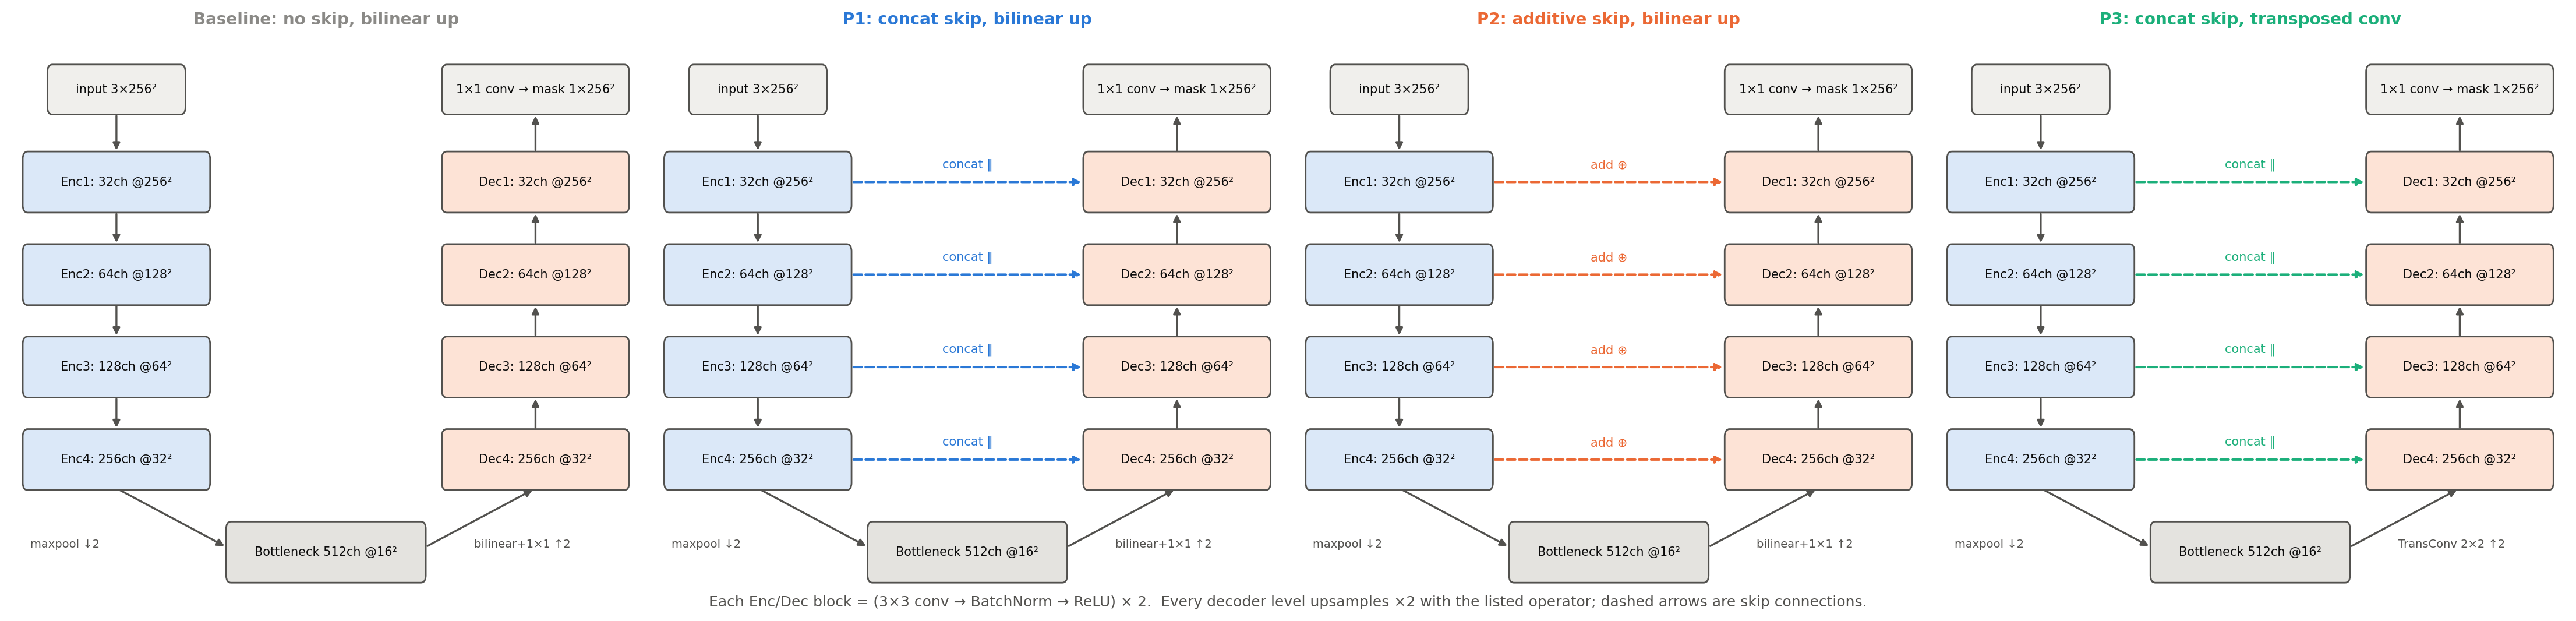


=== RESULTS MAIN METRICS ===


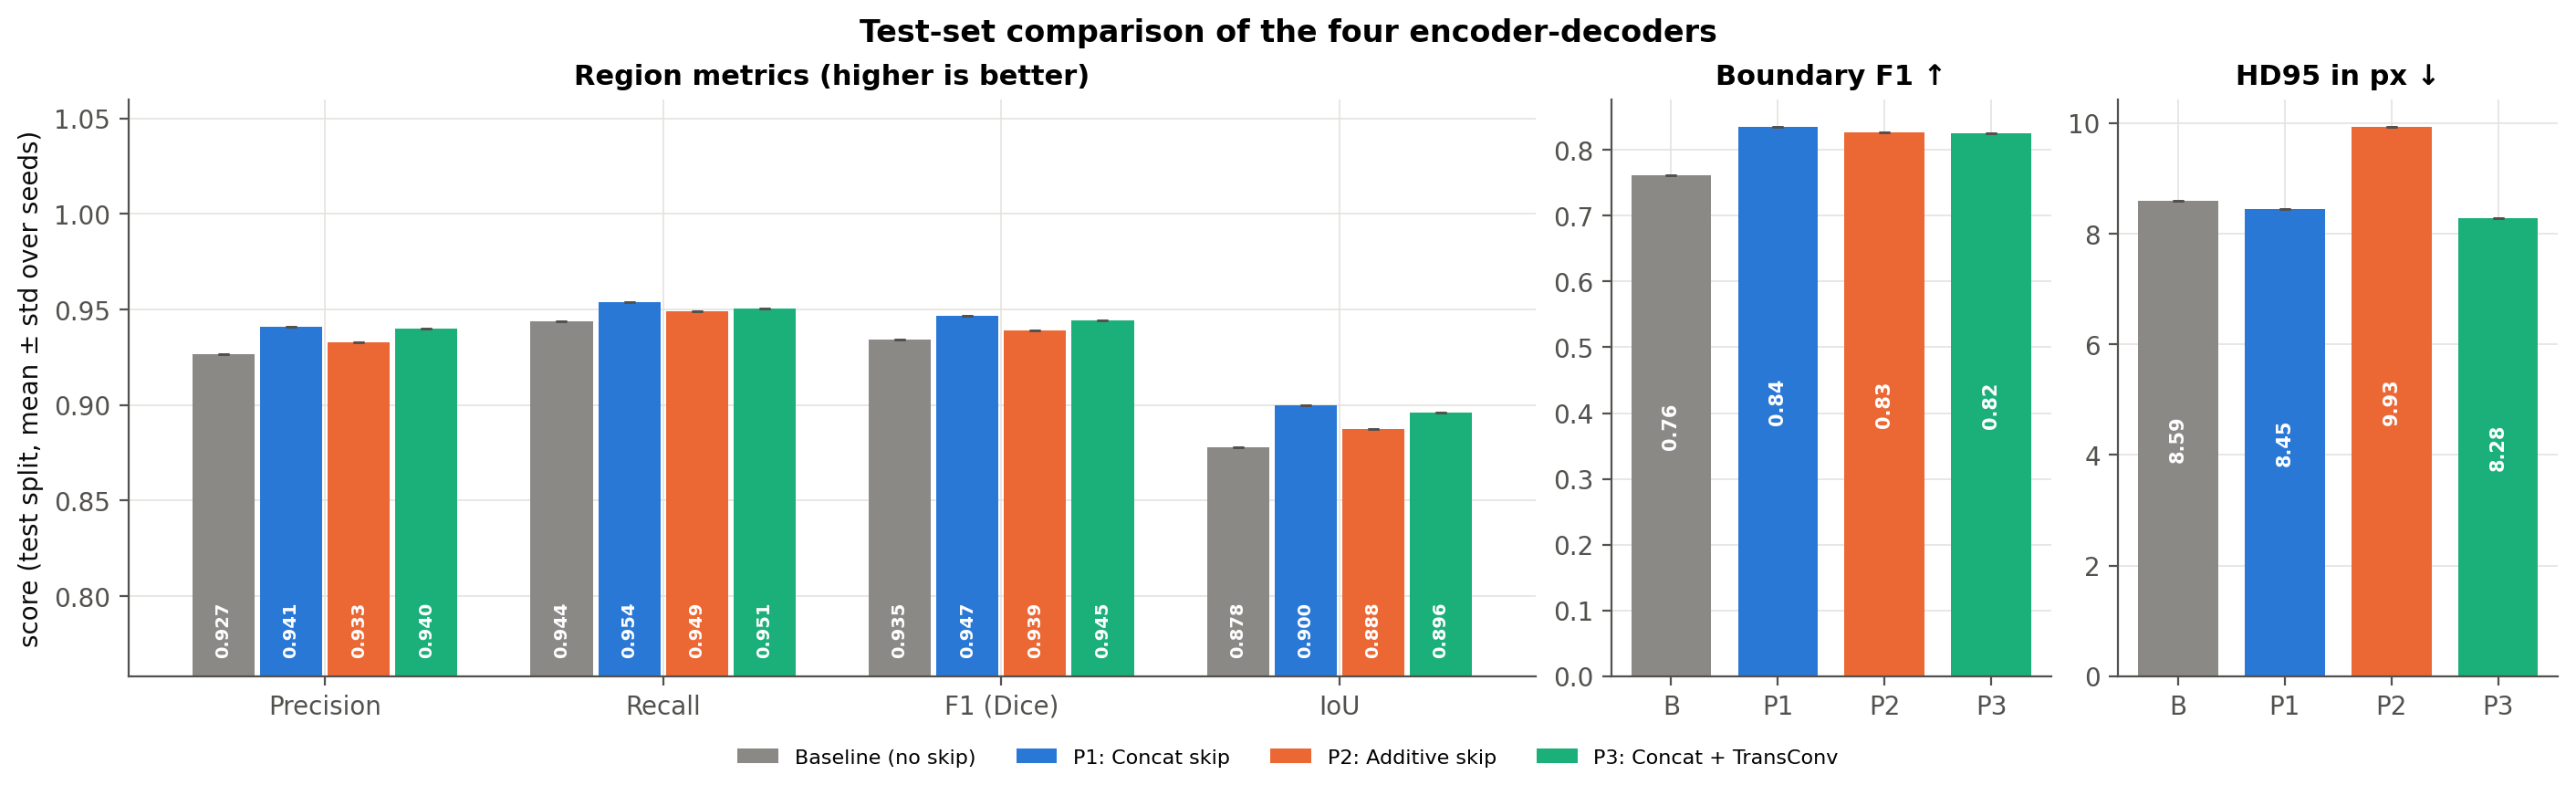


=== OUTLINE TWO EXAMPLES ===


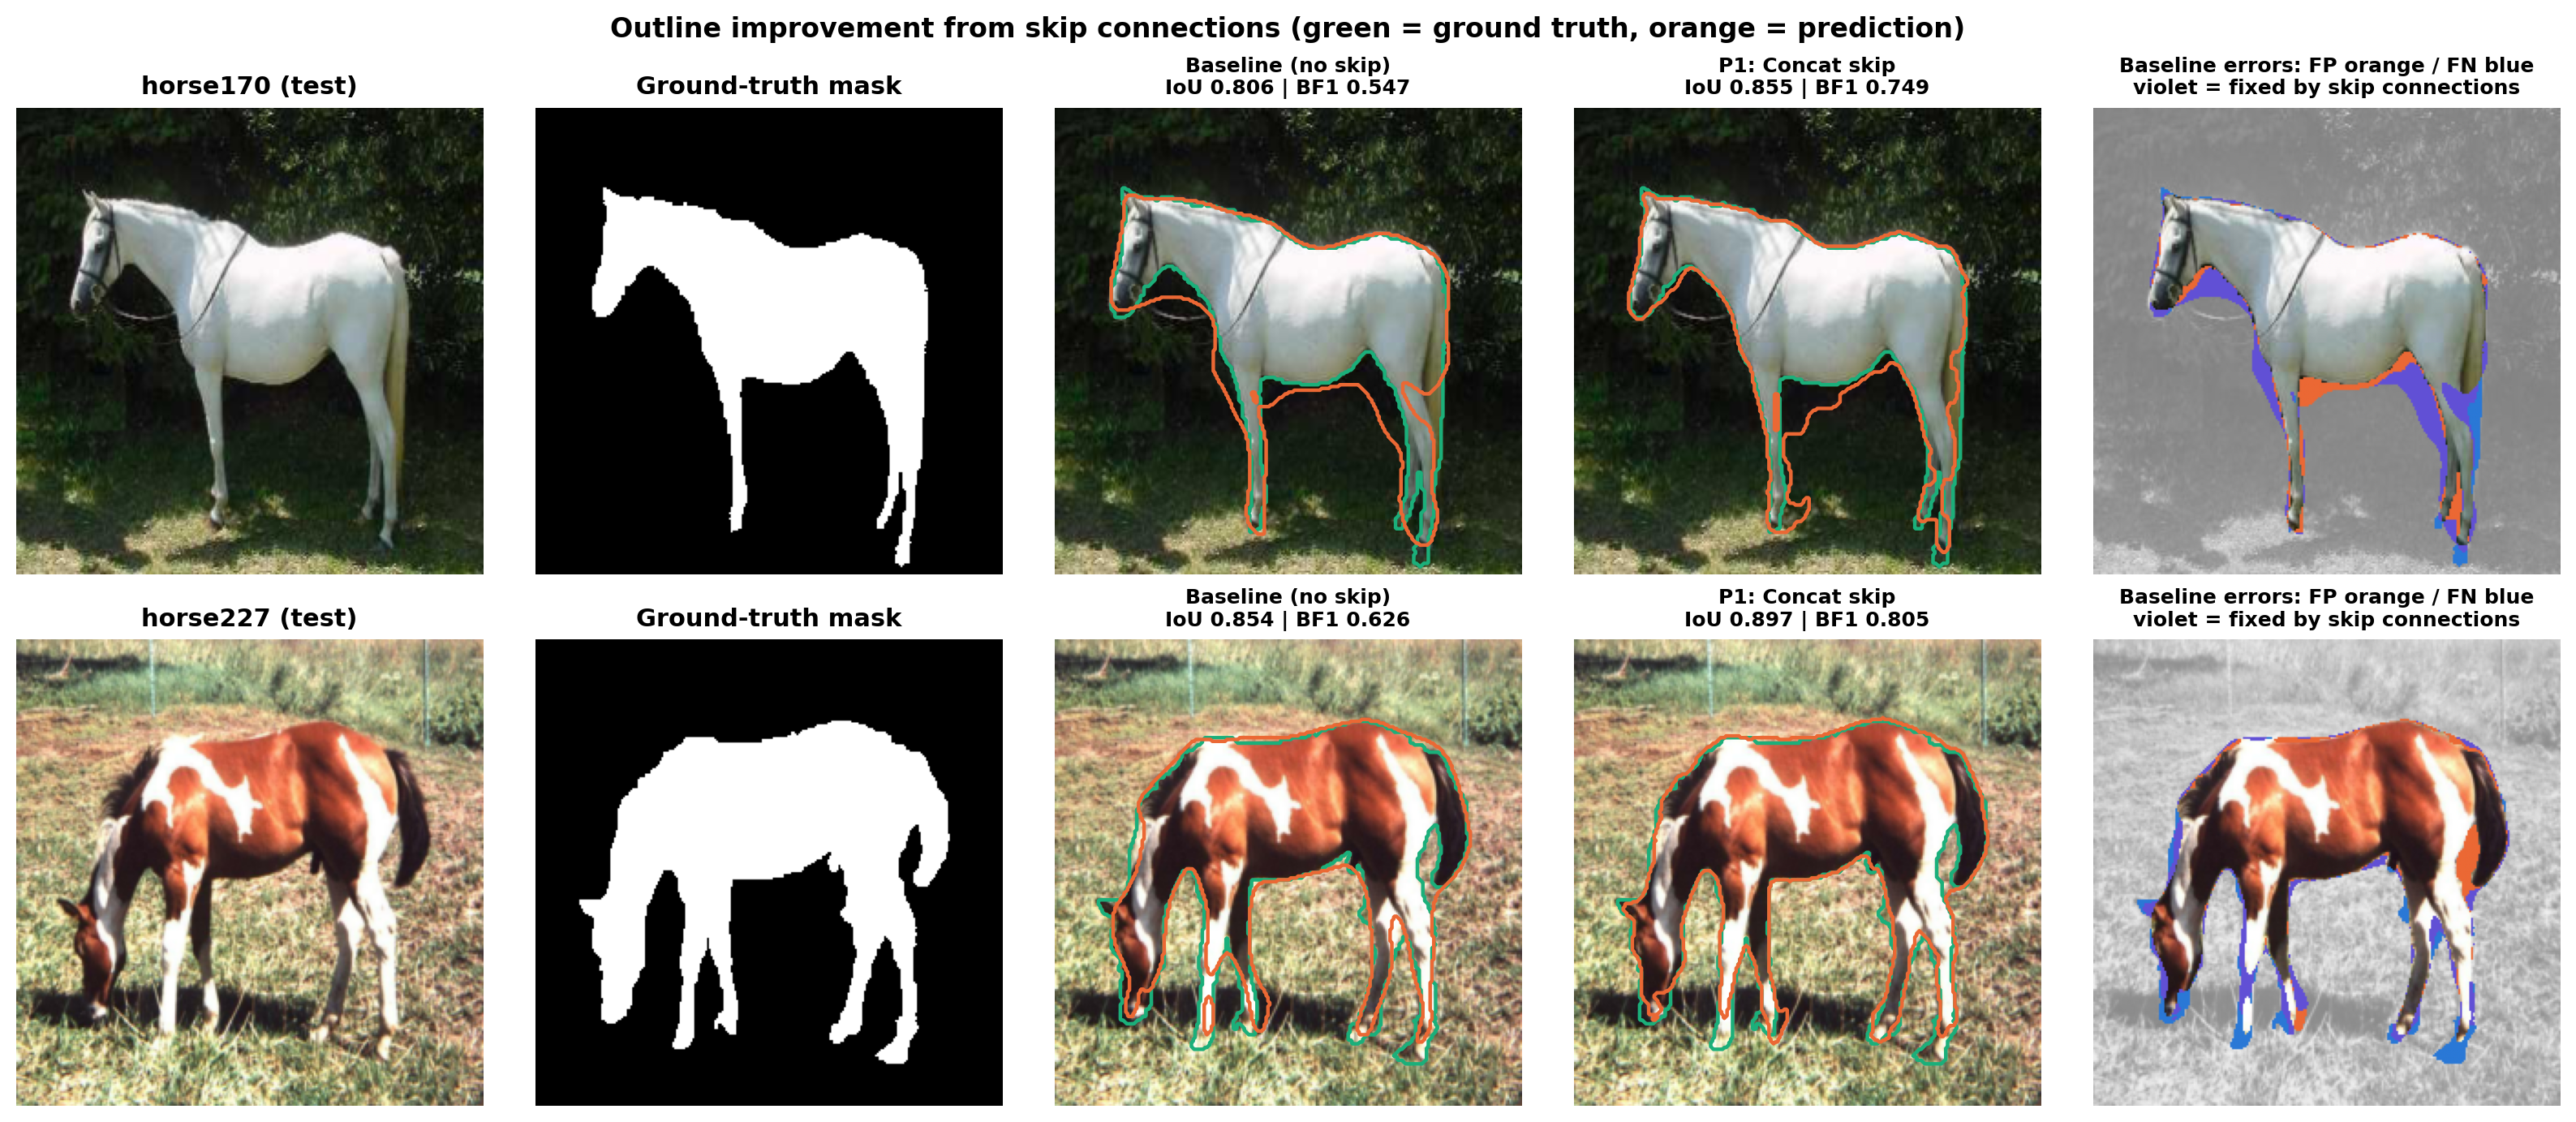


=== ERROR NEAR OUTLINE ===


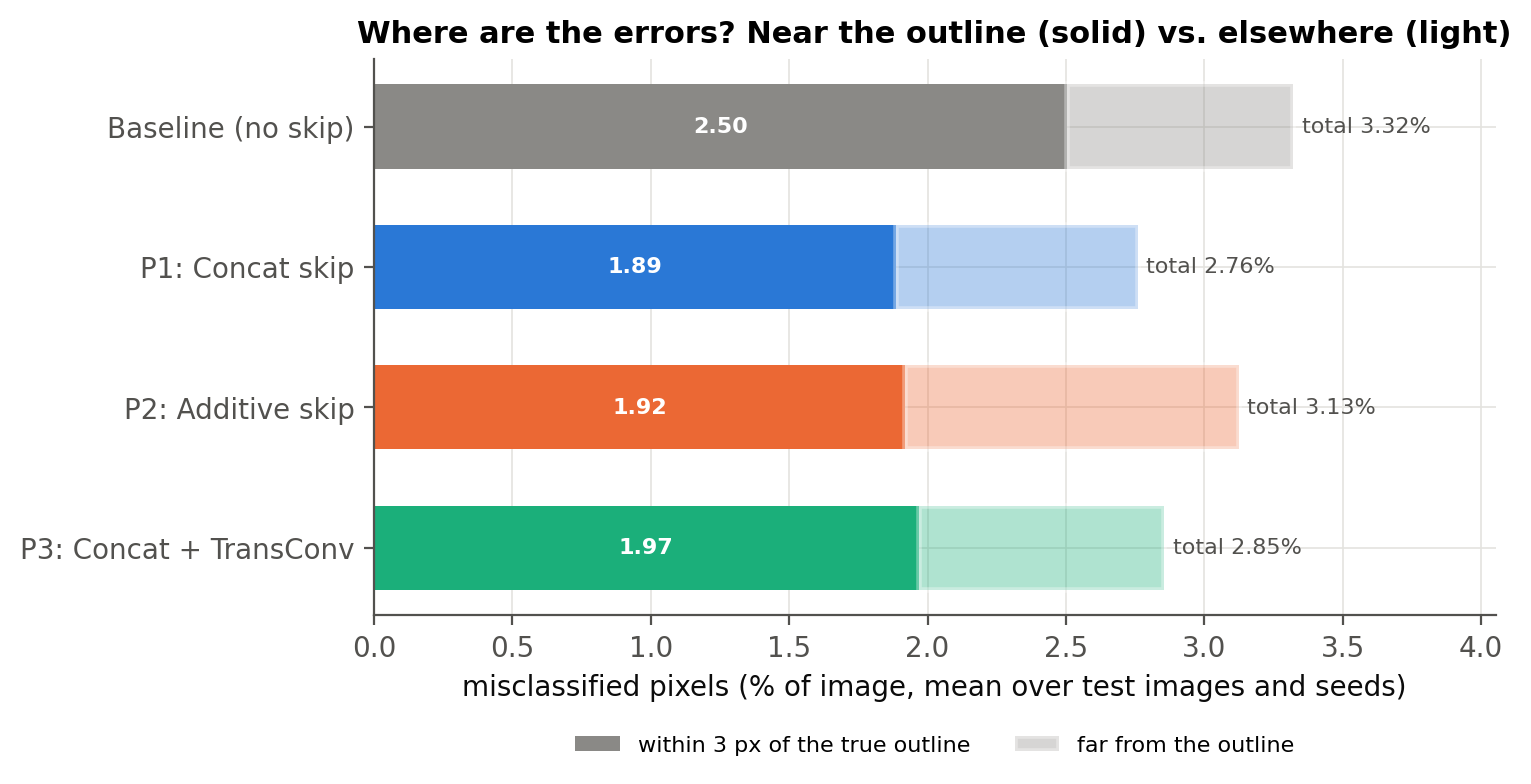


=== SKIP KNOCKOUT ===


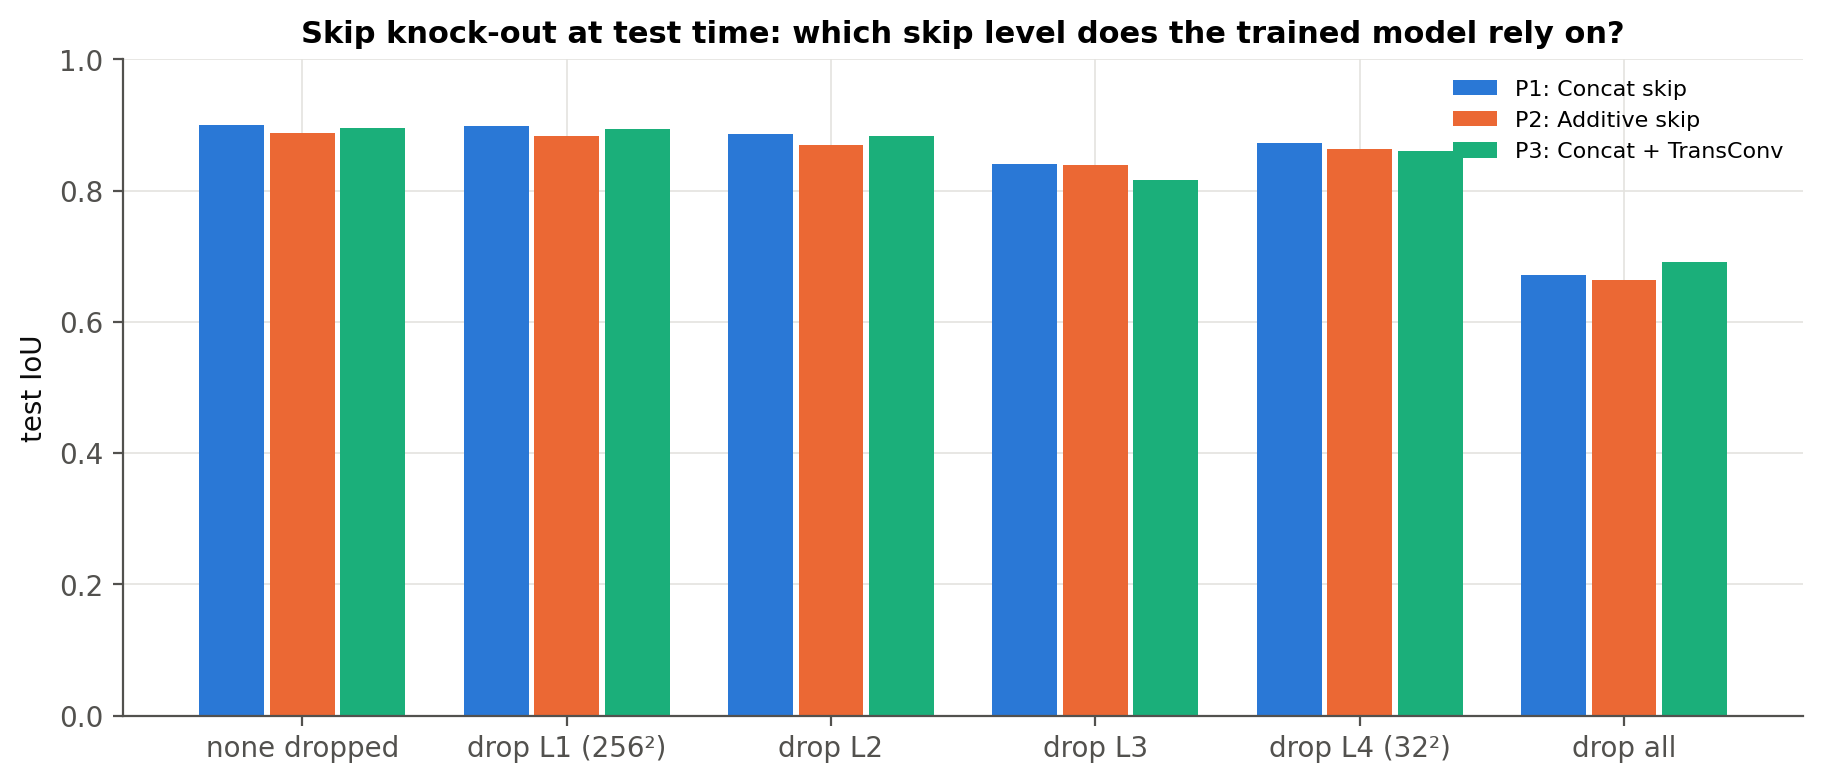


=== TRAINING CURVES ===


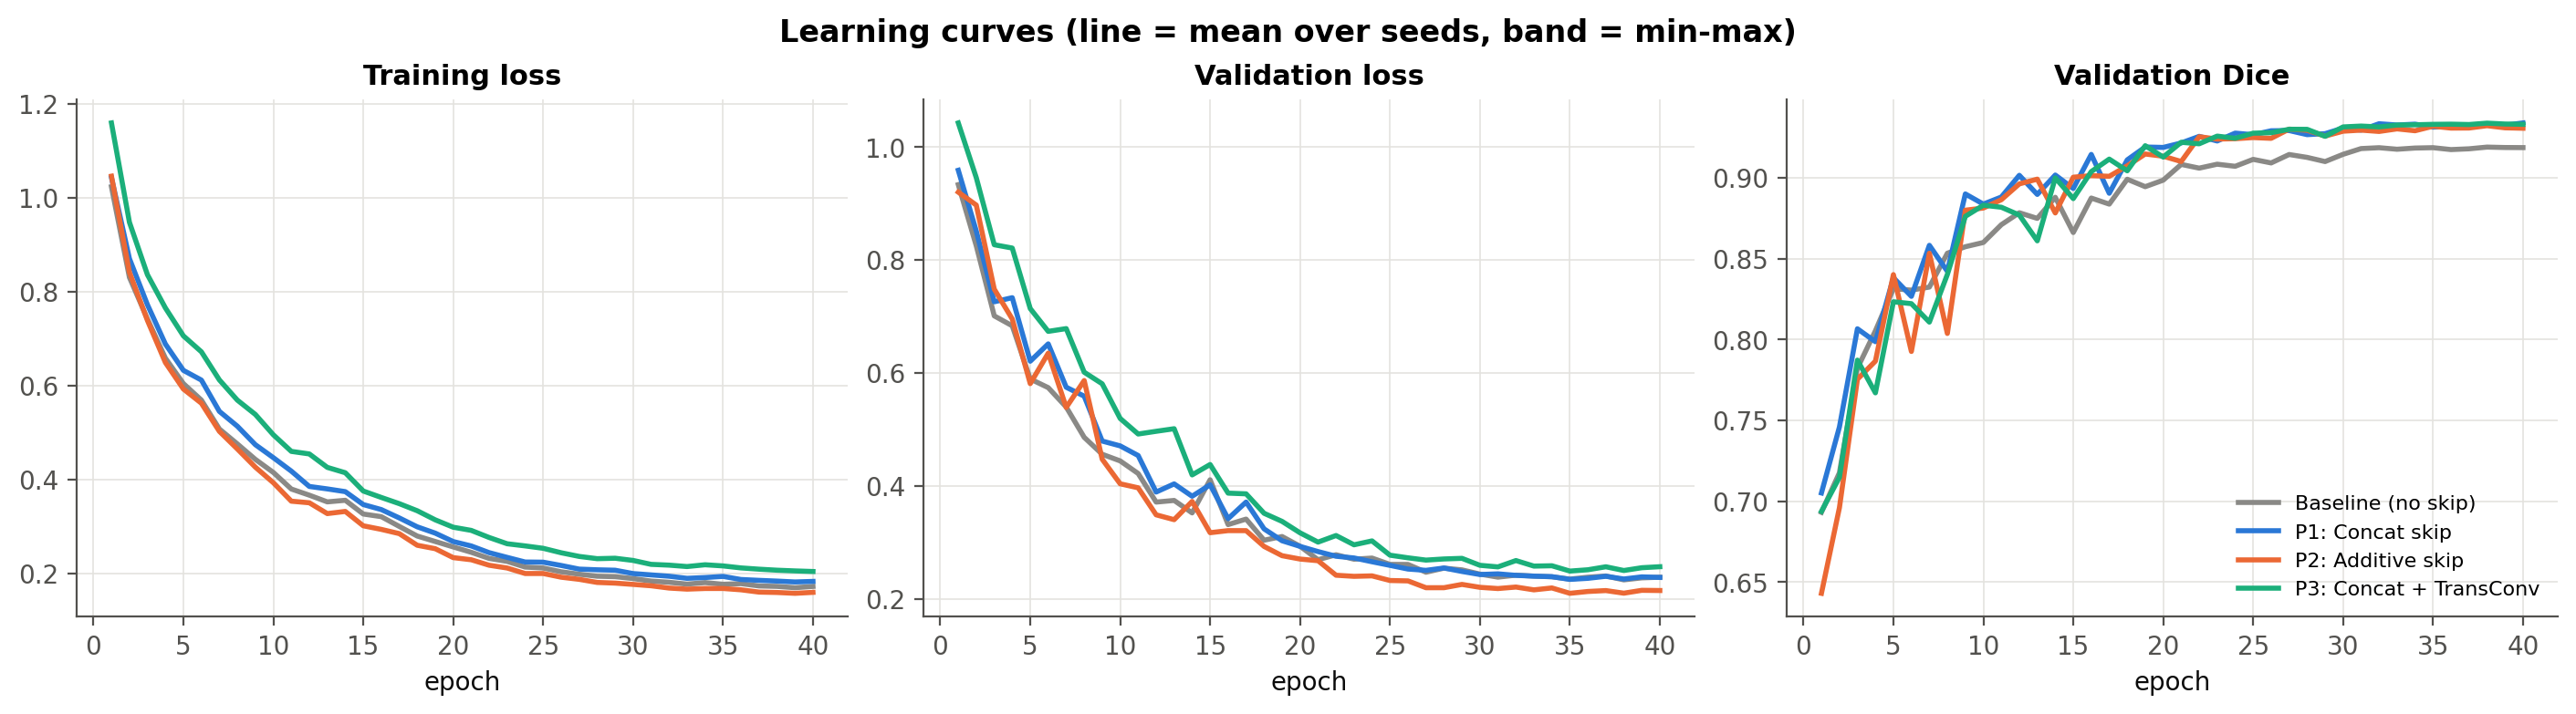


=== RESULTS BY HORSE SIZE ===


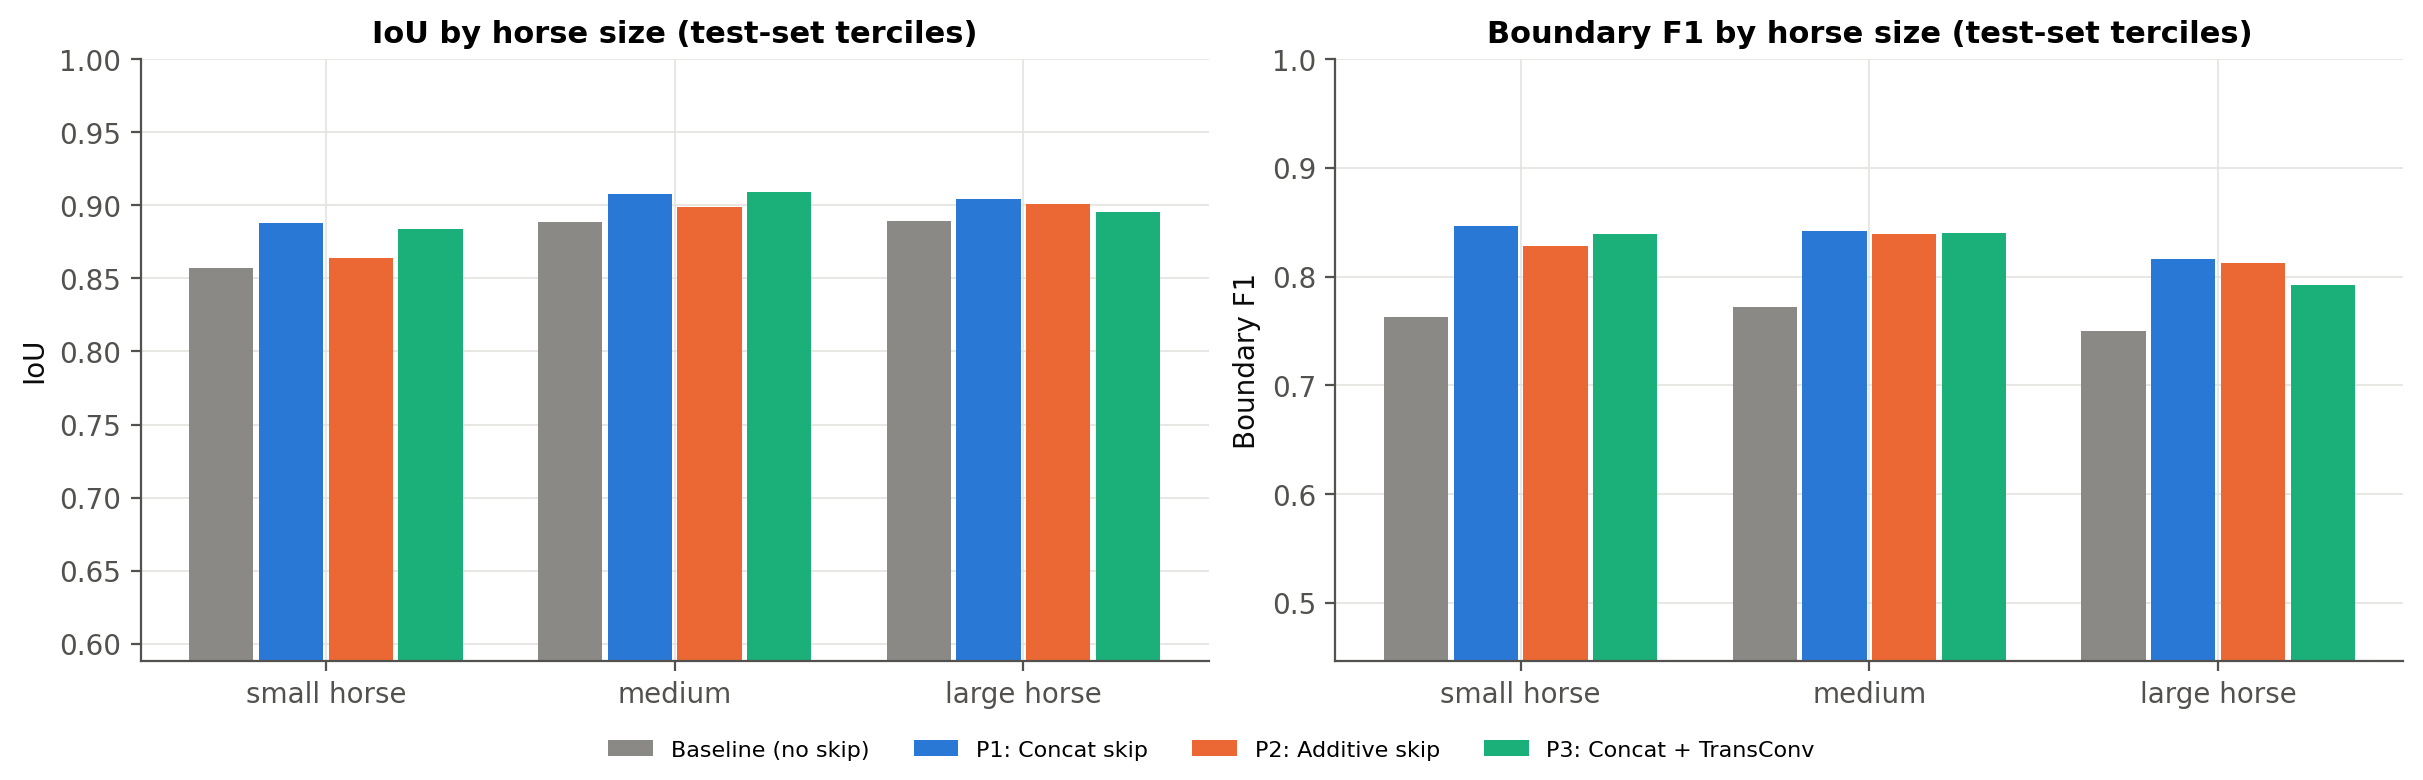


=== QUALITATIVE RANDOM ===


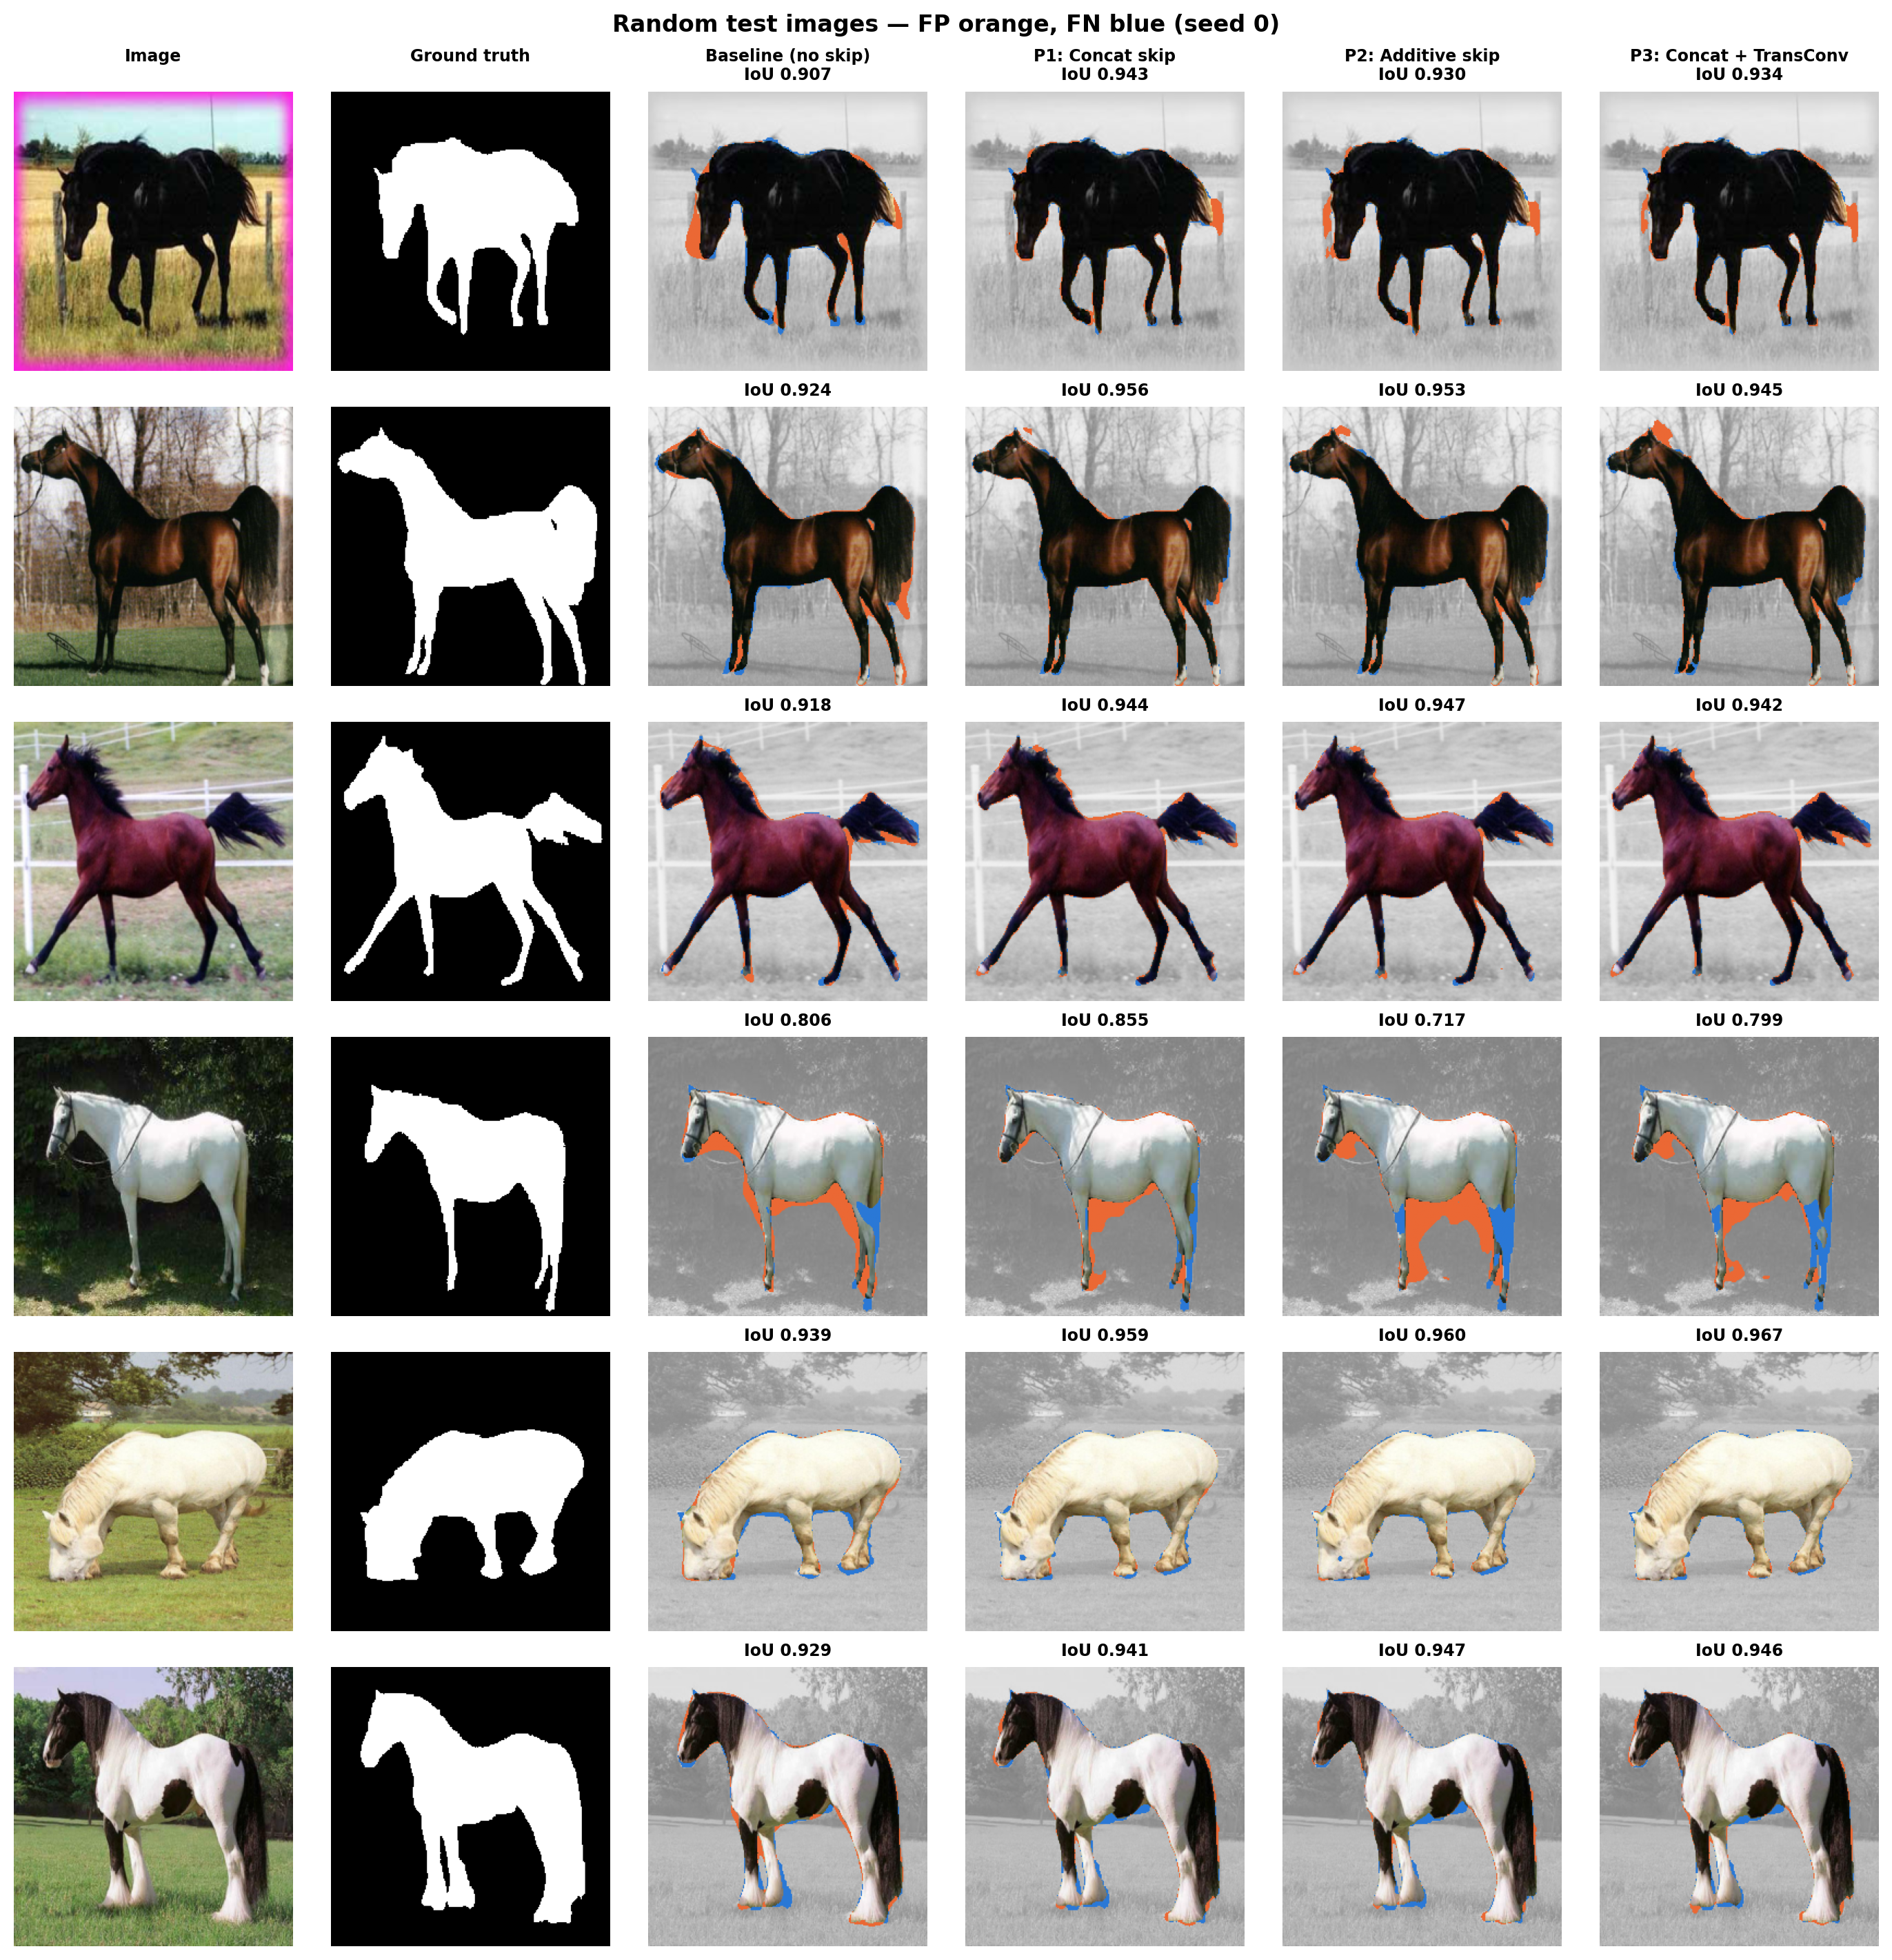


=== QUALITATIVE FAILURES ===


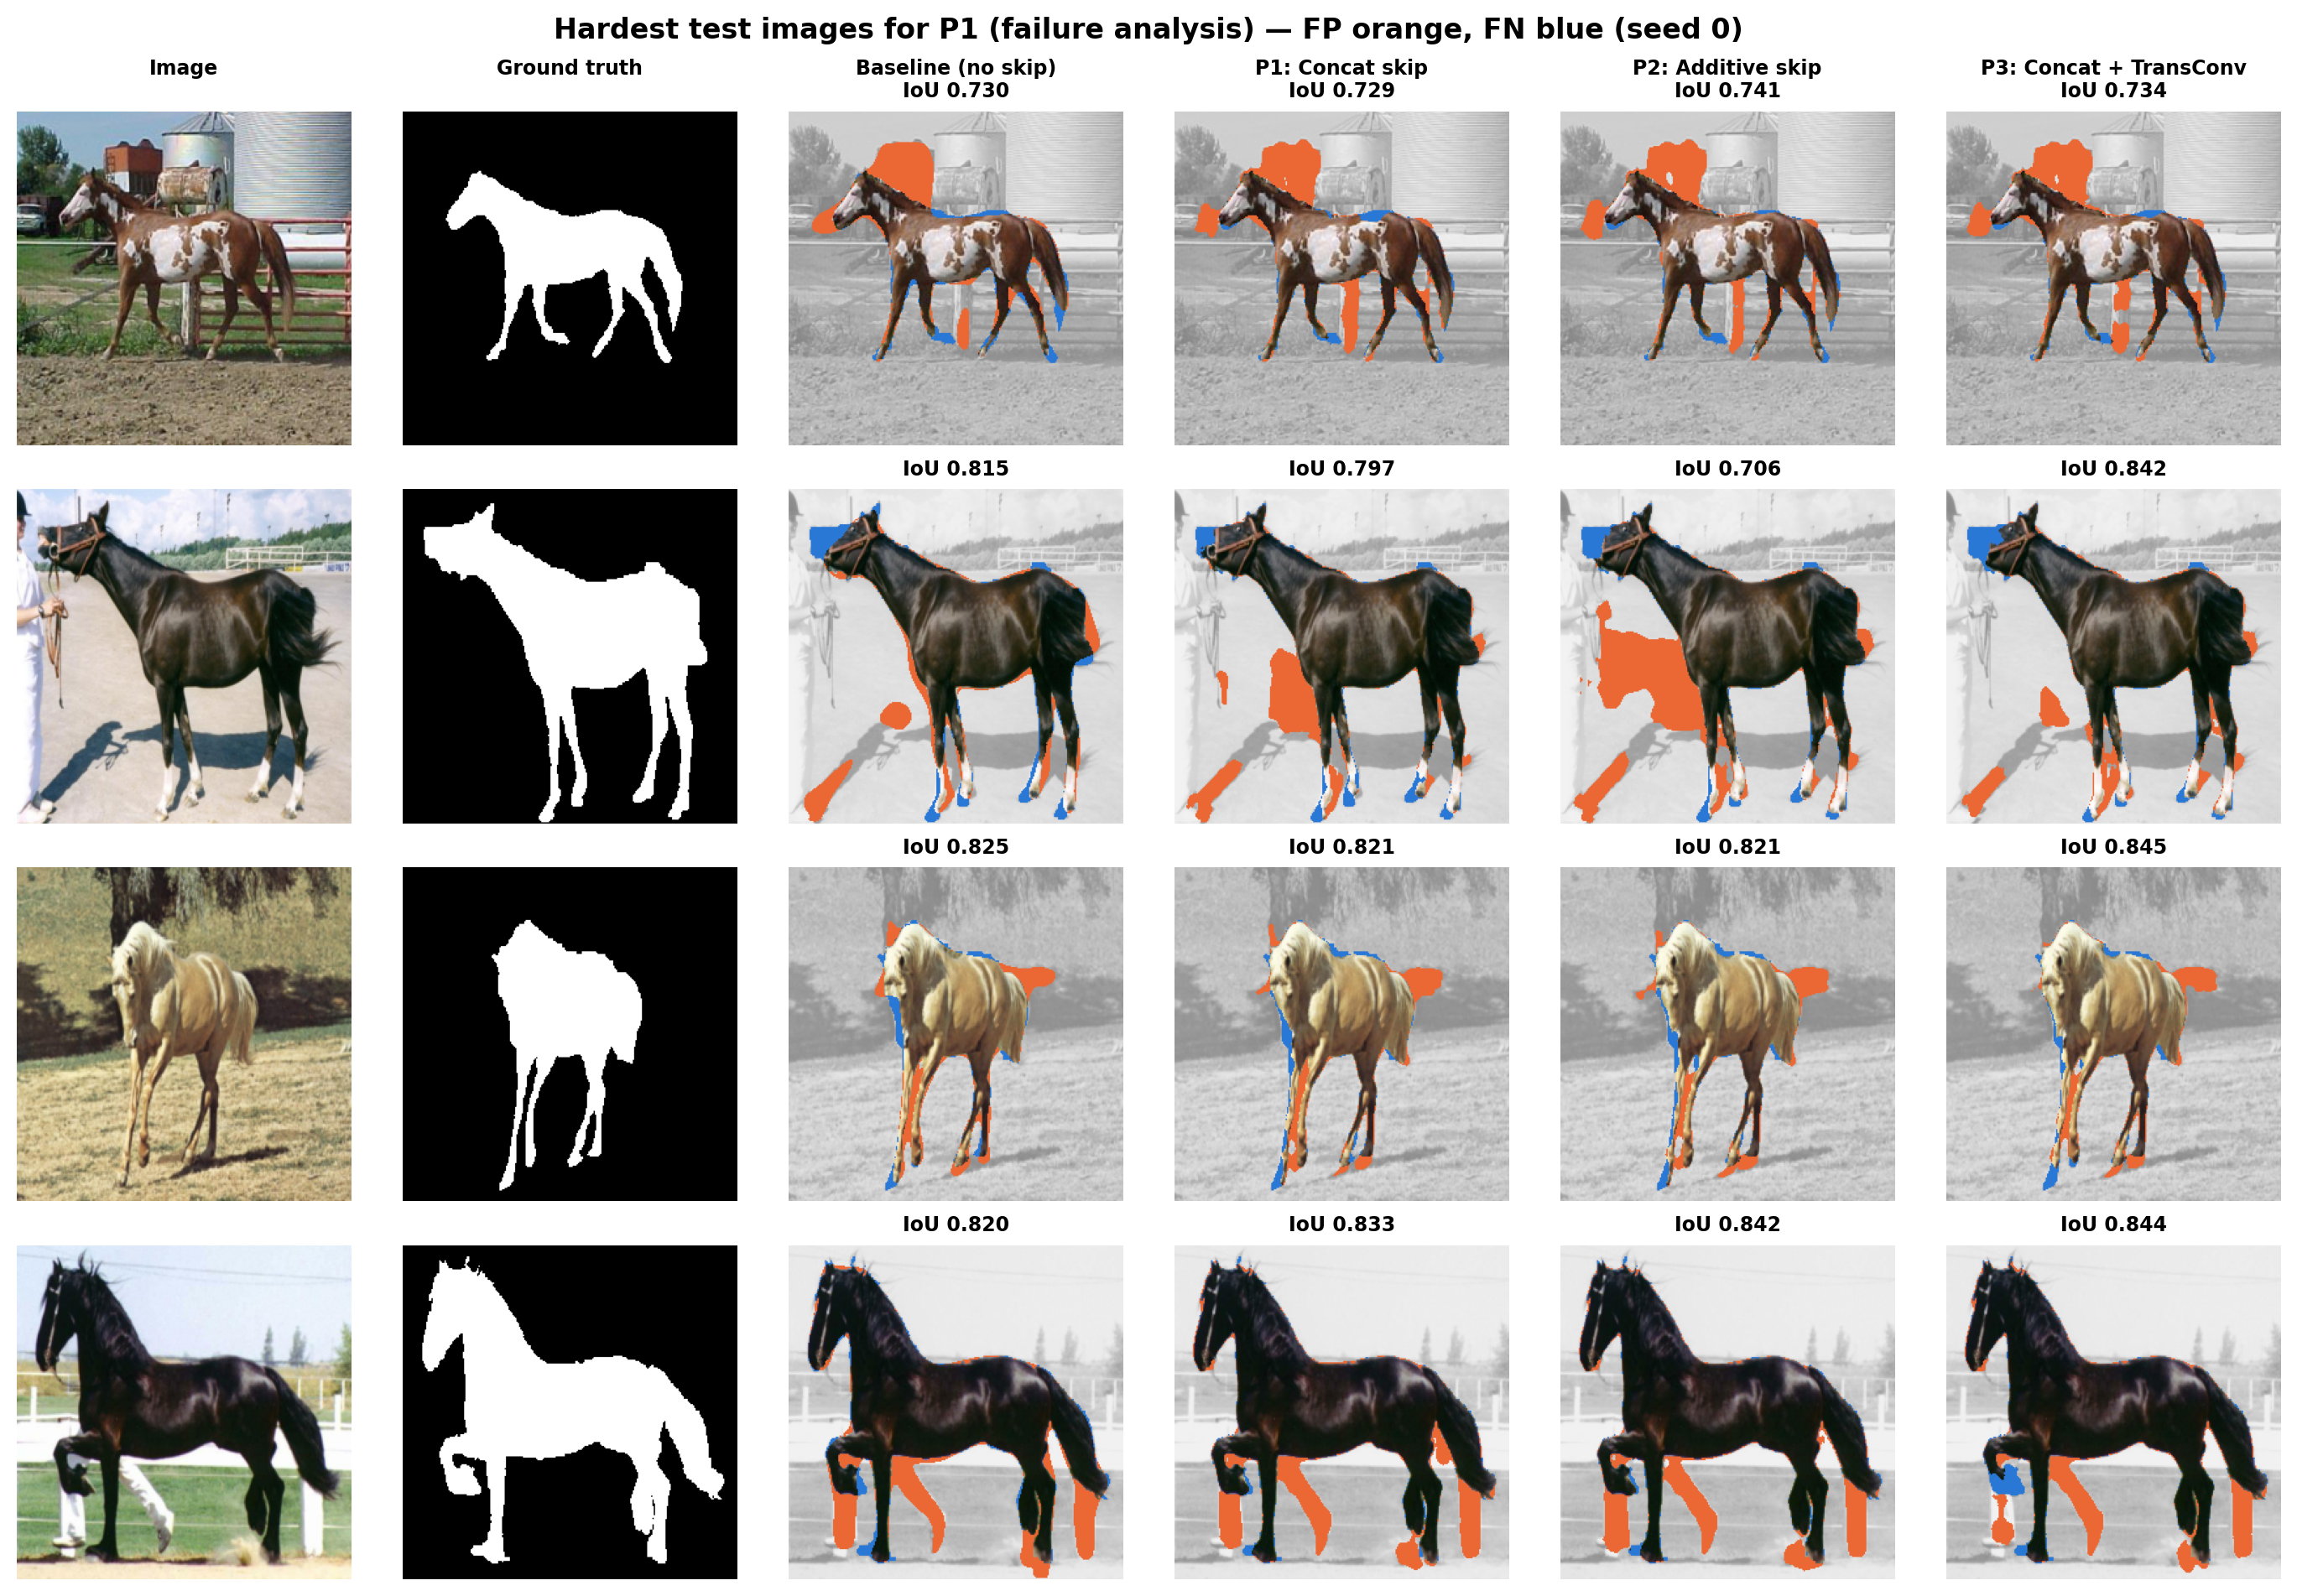


=== EFFICIENCY ===


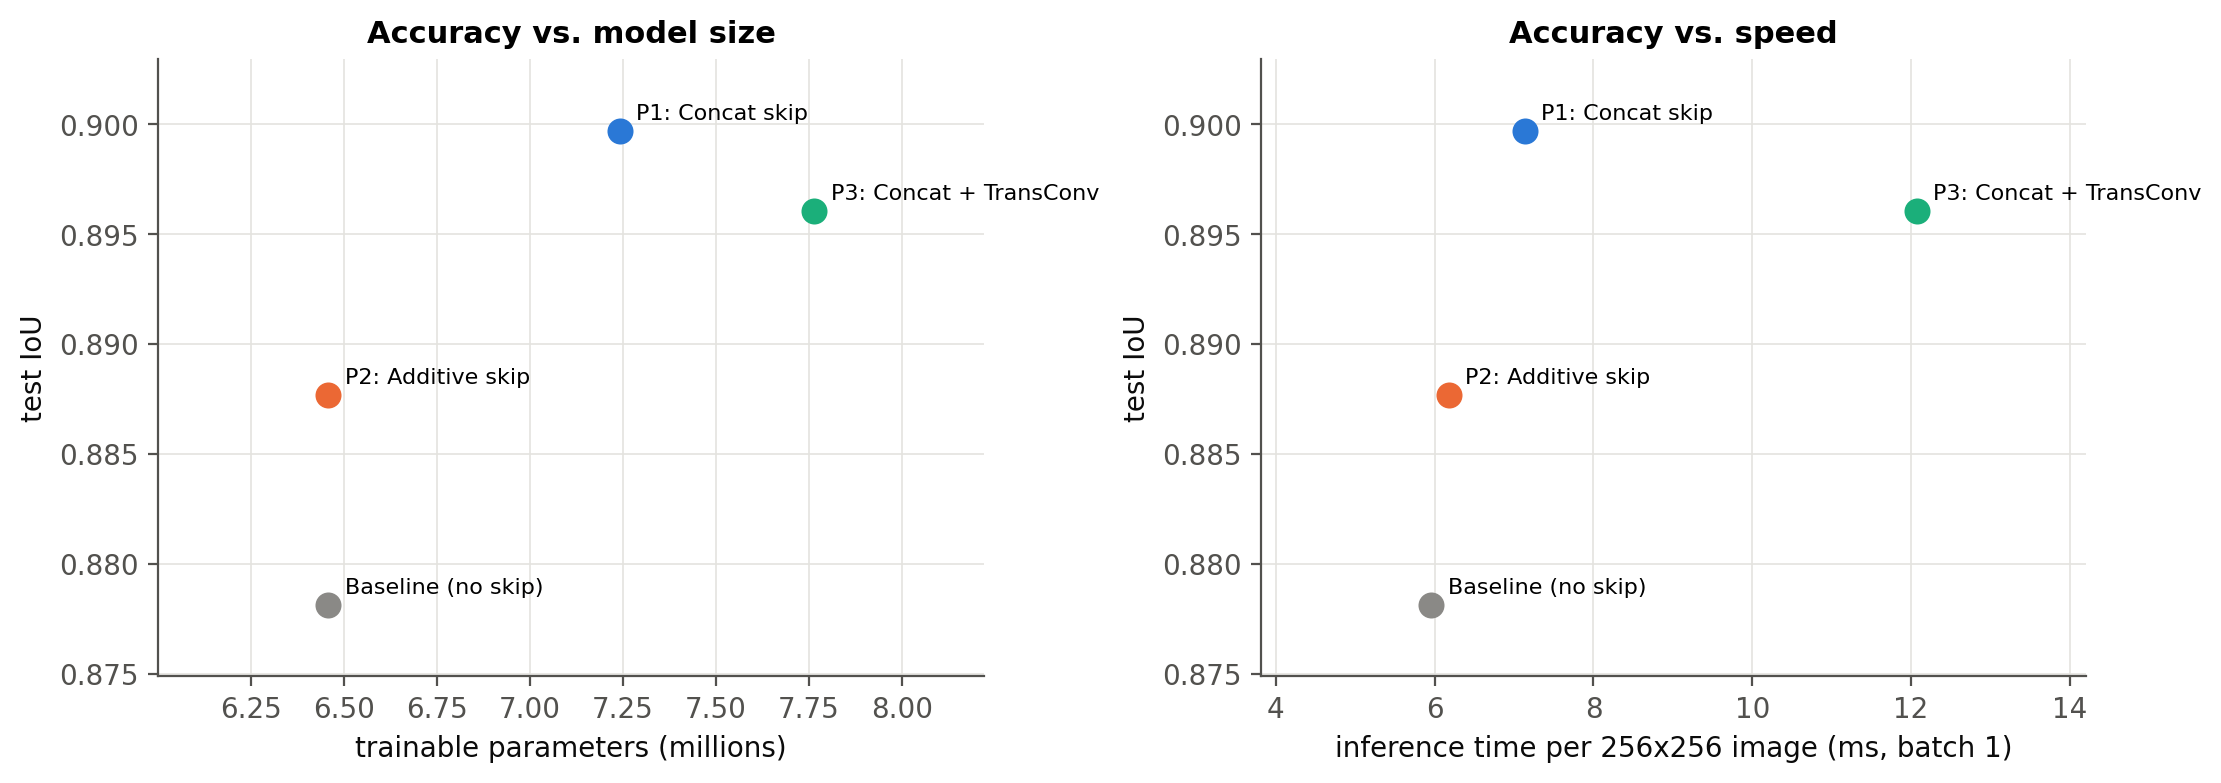

In [9]:
# Display comparison figures
FIGS = [
    "architecture", "results_main_metrics", "outline_two_examples",
    "error_near_outline", "skip_knockout", "training_curves",
    "results_by_horse_size", "qualitative_random", "qualitative_failures", "efficiency"
]
for f in FIGS:
    p = f"{RESULTS_DIR}/figures/{f}.png"
    if os.path.exists(p):
        title = f.upper().replace("_", " ")
        print(f"\n=== {title} ===")
        display(Image(p, width=900))

## 5. Export Results Archive
Packages all tables, figures, logs, and summaries for submission.

In [ ]:
!zip -q -r horse_results.zip {RESULTS_DIR} -x "*/checkpoints/*" "*/predictions/*"
print("✔ horse_results.zip generated successfully!")
try:
    from google.colab import files
    files.download("horse_results.zip")
except Exception:
    print("Note: In VS Code, right-click horse_results.zip in the file panel to download.")